In [15]:
library(report)
library(lme4)
library(lmerTest)
library(BayesFactor)
source('bayesMannWhitney.R')

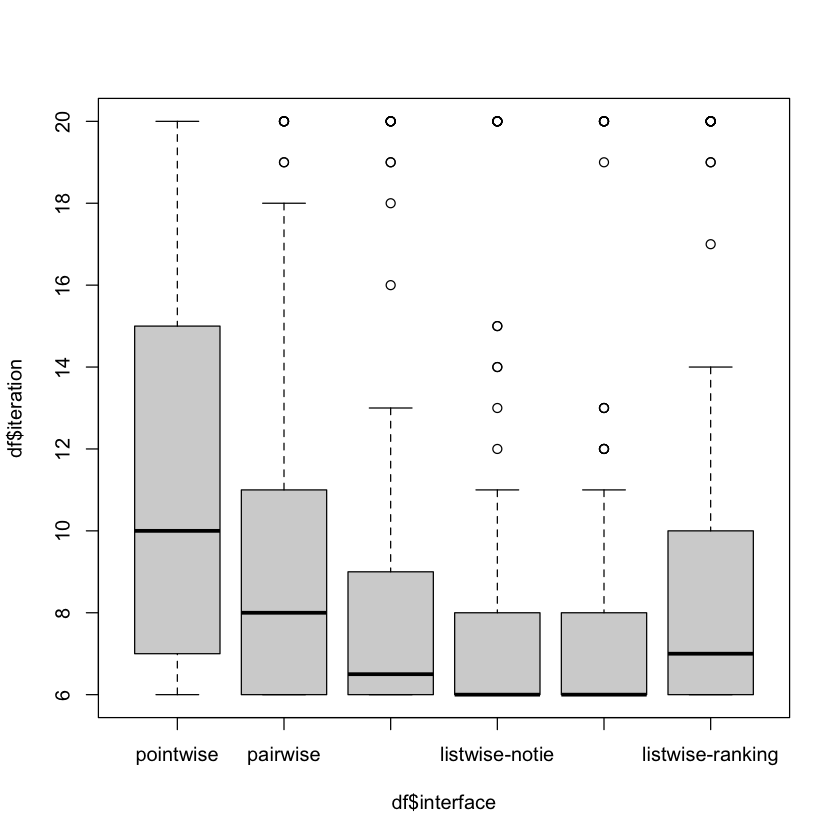

In [16]:
df <- read.csv('processed/iterations.csv')
df$interface = factor(df$interface, levels = c('pointwise', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie', 'listwise-ranking'), ordered=FALSE)
boxplot(df$iteration ~ df$interface)

In [17]:
# H1
df1 <- df[df$interface == 'pointwise',]
df2 <- df[df$interface == 'pairwise',]
r <- report(wilcox.test(df1$iteration, df2$iteration))
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$iteration and df2$iteration suggests that the effect is
positive, statistically significant, and small (W = 4789.50, p = 0.023; r (rank
biserial) = 0.20, 95% CI [0.03, 0.35])


In [18]:
# H2a
df1 <- df[df$interface == 'pointwise',]
df2 <- df[df$interface == 'listwise-rating',]
r <- report(wilcox.test(df1$iteration, df2$iteration))
print(r, verbose=TRUE)

# H2a
df1 <- df[df$interface == 'pairwise',]
df2 <- df[df$interface == 'listwise-cantie',]
r <- report(wilcox.test(df1$iteration, df2$iteration))
print(r, verbose=TRUE)

Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$iteration and df2$iteration suggests that the effect is
positive, statistically significant, and very large (W = 5764.50, p < .001; r
(rank biserial) = 0.42, 95% CI [0.28, 0.55])
Effect sizes were labelled following Funder's (2019) recommendations.

The Wilcoxon rank sum test with continuity correction testing the difference in
ranks between df1$iteration and df2$iteration suggests that the effect is
positive, statistically significant, and large (W = 5259.00, p < .001; r (rank
biserial) = 0.31, 95% CI [0.15, 0.46])


  |**************************************************| 100%

[1] 10.97165

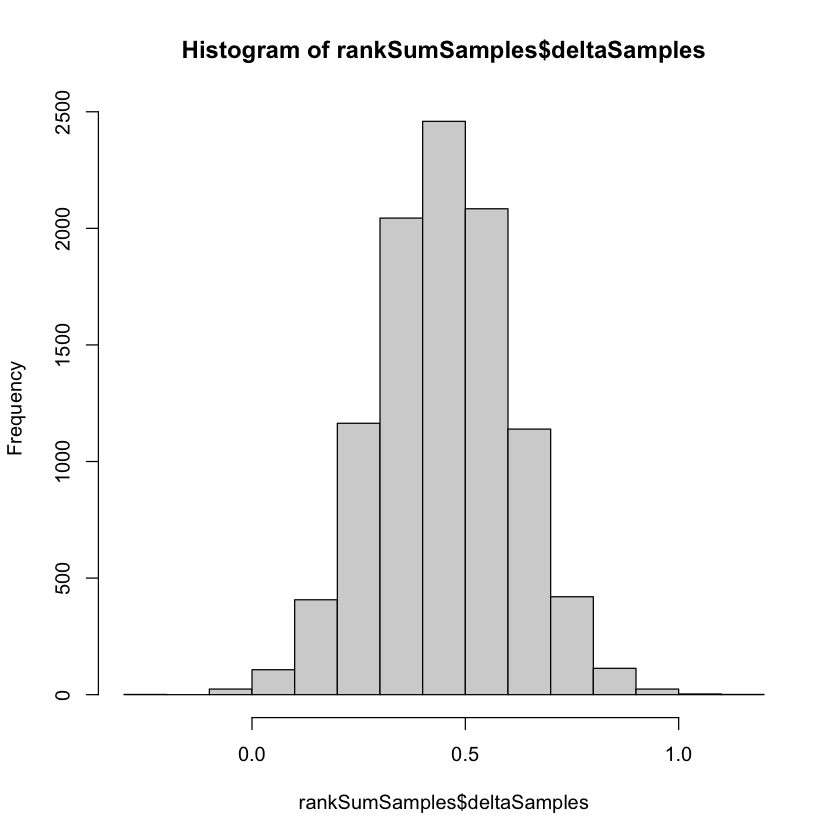

In [19]:
x <- df1$iteration
y <- df2$iteration

# Default Cauchy prior width is set to 1/sqrt(2) for the sampler 
rankSumSamples <- rankSumGibbsSampler(xVals = x, yVals = y)
hist(rankSumSamples$deltaSamples)
computeBayesFactorOneZero(rankSumSamples$deltaSamples, whichTest = "Wilcoxon", priorParameter = 1 / sqrt(2))

In [20]:
df <- read.csv("processed/iterations.csv")
df <- df[df$interface != 'pointwise',]
df <- df[df$interface != 'pairwise',]
df <- df[df$interface != 'listwise-ranking',]

df$interface <- factor(df$interface, levels = c('listwise-cantie', 'listwise-rating', 'listwise-notie'), ordered=FALSE)
# H3
m <- glmer(iteration ~ interface + (1|userID), data = df, family = poisson)
summary(m)
print(report(m), verbose=TRUE)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: poisson  ( log )
Formula: iteration ~ interface + (1 | userID)
   Data: df

     AIC      BIC   logLik deviance df.resid 
  1422.1   1436.5   -707.1   1414.1      266 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.5782 -0.4767 -0.2942  0.1454  3.2975 

Random effects:
 Groups Name        Variance Std.Dev.
 userID (Intercept) 0.07054  0.2656  
Number of obs: 270, groups:  userID, 90

Fixed effects:
                         Estimate Std. Error z value Pr(>|z|)    
(Intercept)              2.067028   0.061400  33.665   <2e-16 ***
interfacelistwise-rating 0.044867   0.086234   0.520    0.603    
interfacelistwise-notie  0.006696   0.086545   0.077    0.938    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
              (Intr) intrfclstws-r
intrfclstws-r -0.709              
intrfclstws-n -0.705  0.502       

We fitted a poisson mixed model (estimated using ML and Nelder-Mead optimizer)
to predict iteration with interface
 (formula: iteration ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.38) and the part related to the fixed effects
alone (marginal R2) is of 2.08e-03. The model's intercept, corresponding to
interface = listwise-cantie
, is at 2.07 (95% CI [1.95, 2.19], p < .001). Within this model:

  - The effect of interface [listwise-rating] is statistically non-significant
and positive (beta = 0.04, 95% CI [-0.12, 0.21], p = 0.603; Std. beta = 0.04,
95% CI [-0.12, 0.21])
  - The effect of interface [listwise-notie] is statistically non-significant and
positive (beta = 6.70e-03, 95% CI [-0.16, 0.18], p = 0.938; Std. beta =
6.70e-03, 95% CI [-0.16, 0.18])

Standardized parameters were obtained by fitting the model on a standardized
version of the dataset. 95% Confidence Intervals (CI

In [21]:
df <- read.csv("processed/iterations.csv")
df <- df[df$interface != 'pointwise',]

df$interface <- factor(df$interface, levels = c('listwise-ranking', 'pairwise', 'listwise-rating', 'listwise-notie', 'listwise-cantie'), ordered=FALSE)
# H4
m <- glmer(iteration ~ interface + (1|userID), data = df, family = poisson)
summary(m)
print(report(m), verbose=TRUE)

Generalized linear mixed model fit by maximum likelihood (Laplace
  Approximation) [glmerMod]
 Family: poisson  ( log )
Formula: iteration ~ interface + (1 | userID)
   Data: df

     AIC      BIC   logLik deviance df.resid 
  2443.0   2467.6  -1215.5   2431.0      443 

Scaled residuals: 
    Min      1Q  Median      3Q     Max 
-1.9847 -0.5384 -0.2927  0.2966  3.2953 

Random effects:
 Groups Name        Variance Std.Dev.
 userID (Intercept) 0.07111  0.2667  
Number of obs: 449, groups:  userID, 150

Fixed effects:
                         Estimate Std. Error z value Pr(>|z|)    
(Intercept)               2.20048    0.06007  36.631   <2e-16 ***
interfacepairwise         0.04952    0.08456   0.586    0.558    
interfacelistwise-rating -0.08872    0.08545  -1.038    0.299    
interfacelistwise-notie  -0.12693    0.08577  -1.480    0.139    
interfacelistwise-cantie -0.13362    0.08582  -1.557    0.119    
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation o

We fitted a poisson mixed model (estimated using ML and Nelder-Mead optimizer)
to predict iteration with interface
 (formula: iteration ~ interface). The model included userID
 as random effect (formula: ~1 | userID). The model's total explanatory power is
substantial (conditional R2 = 0.41) and the part related to the fixed effects
alone (marginal R2) is of 0.03. The model's intercept, corresponding to
interface = listwise-ranking
, is at 2.20 (95% CI [2.08, 2.32], p < .001). Within this model:

  - The effect of interface [pairwise] is statistically non-significant and
positive (beta = 0.05, 95% CI [-0.12, 0.22], p = 0.558; Std. beta = 0.05, 95%
CI [-0.12, 0.22])
  - The effect of interface [listwise-rating] is statistically non-significant
and negative (beta = -0.09, 95% CI [-0.26, 0.08], p = 0.299; Std. beta = -0.09,
95% CI [-0.26, 0.08])
  - The effect of interface [listwise-notie] is statistically non-significant and
negative (beta = -0.13, 95% CI [-0.30, 0.04], p = 0.139; Std. b